# 1.0 - Exploración y Extracción de Features para P3 (Clustering de Estaciones)

**Autor:** AT (Ariadna Tapia)  
**Pregunta 3 (P3):** ¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?  
**Objetivo:** Explorar las distribuciones de viajes por estación, validar la lógica de agregaciones temporales/espaciales y consumir la función de ingeniería de características desde el módulo `mibici_mlops.featuresp3` respetando las buenas prácticas de Cookiecutter Data Science (la lógica vive en el módulo, el notebook es únicamente para exploración y validación visual).

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Añadir directorio raíz del proyecto si es necesario
project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from mibici_mlops import config
from mibici_mlops.featuresp3 import generate_p3_station_features

sns.set_theme(style="whitegrid")
print("Configuración y módulos importados correctamente.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


2026-10-18 09:17:33.866 | INFO     | mibici_mlops.config:<module>:11 - PROJ_ROOT path is: C:\Users\arita\Documents\MLOPs\TC5061-Proyecto-Equipo51


Configuración y módulos importados correctamente.


## 1. Carga de Datos Procesados (Enero 2024 - Septiembre 2026)
Cargamos los datasets limpios y particionados en Apache Parquet desde `data/processed/`.

In [3]:
trips_path = config.PROCESSED_DATA_DIR / "trips"
nomenclature_path = config.PROCESSED_DATA_DIR / "nomenclature"

print(f"Cargando viajes desde: {trips_path}")
trips_df = pd.read_parquet(trips_path)

print(f"Cargando nomenclatura desde: {nomenclature_path}")
stations_df = pd.read_parquet(nomenclature_path)

print(f"Total registros de viajes cargados: {len(trips_df):,}")
print(f"Total estaciones en catálogo: {len(stations_df):,}")

Cargando viajes desde: C:\Users\arita\Documents\MLOPs\TC5061-Proyecto-Equipo51\data\processed\trips
Cargando nomenclatura desde: C:\Users\arita\Documents\MLOPs\TC5061-Proyecto-Equipo51\data\processed\nomenclature
Total registros de viajes cargados: 12,539,260
Total estaciones en catálogo: 484


## 2. Inspección Exploratoria Inicial
Revisamos una muestra de viajes y del catálogo de nomenclatura para verificar esquemas y tipos de datos.

In [4]:
display(trips_df.head())
display(stations_df.head())

,viaje_id,usuario_id,genero,ano_de_nacimiento,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,31789291,640715,M,1984.0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,31789292,2353010,F,1995.0,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,31789293,1556365,M,1984.0,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,31789294,2626233,M,1994.0,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,31789295,2602006,M,1998.0,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154


,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


## 3. Extracción de Features usando `featuresp3.py`
Invocamos directamente la función `generate_p3_station_features` del módulo para transformar el historial de viajes en un vector multidimensional por estación.

In [5]:
station_features = generate_p3_station_features(trips_df, stations_df)
print(f"Matriz generada: {station_features.shape[0]} estaciones x {station_features.shape[1]} variables")
station_features.head(10)

Matriz generada: 471 estaciones x 7 variables


,latitude,longitude,ratio_am,ratio_pm,pct_fin_semana,pct_domingo,rotacion_capacidad
station_id,,,,,,,
2,20.666378,-103.348820,1.074323,0.848616,0.178116,0.068570,7597.061602
3,20.667228,-103.366000,0.797555,1.480514,0.197410,0.081453,6237.662508
4,20.667690,-103.368252,0.655061,1.467034,0.219649,0.117681,6591.470215
5,20.691847,-103.362549,1.250480,0.582451,0.185233,0.079506,5342.628767
6,20.681158,-103.339363,1.141849,0.574842,0.217102,0.093960,5497.904093
8,20.680717,-103.344415,1.085605,0.819215,0.227025,0.100817,5348.722410
9,20.666771,-103.350562,1.199957,0.656281,0.204910,0.085829,5657.129562
10,20.681953,-103.349992,1.844522,0.708066,0.198572,0.085284,5399.796400
11,20.682077,-103.353835,1.581704,0.986566,0.195083,0.082998,15311.993343


## 4. Análisis Exploratorio de Variables (Distribución y Dispersión)
Analizamos los estadísticos descriptivos y las distribuciones de las características diseñadas para el clustering (ratios AM/PM, uso de fin de semana, rotación por anclaje).

In [6]:
station_features.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,471.0,20.678231,0.021719,20.636130,20.665055,20.674140,20.687992,20.739523
longitude,471.0,-103.361997,0.031692,-103.433215,-103.384183,-103.362351,-103.339371,-103.297112
ratio_am,471.0,1.354579,0.794256,0.090814,0.773952,1.155172,1.719071,4.642854
ratio_pm,471.0,1.118652,0.567419,0.243617,0.684498,0.951177,1.450861,3.434028
pct_fin_semana,471.0,0.216233,0.053729,0.077189,0.184316,0.207701,0.238196,0.461590
pct_domingo,471.0,0.106589,0.048395,0.023215,0.080666,0.093503,0.117850,0.386872
rotacion_capacidad,471.0,3125.322882,3313.506018,11.315784,748.511834,2050.798633,4861.301670,28956.047363


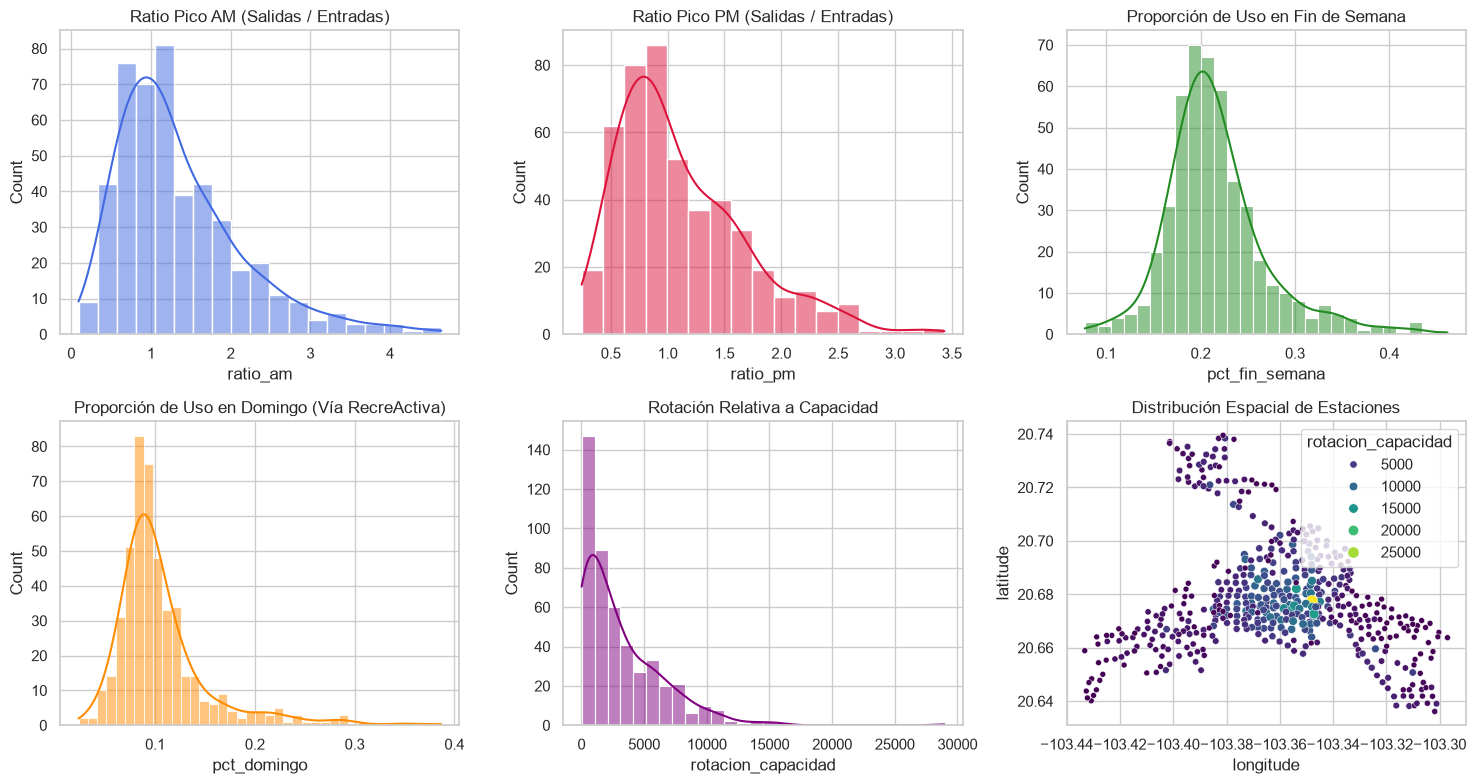

In [7]:
# Distribución de variables clave de movilidad
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

sns.histplot(station_features["ratio_am"], kde=True, ax=axes[0, 0], color="royalblue")
axes[0, 0].set_title("Ratio Pico AM (Salidas / Entradas)")

sns.histplot(station_features["ratio_pm"], kde=True, ax=axes[0, 1], color="crimson")
axes[0, 1].set_title("Ratio Pico PM (Salidas / Entradas)")

sns.histplot(station_features["pct_fin_semana"], kde=True, ax=axes[0, 2], color="forestgreen")
axes[0, 2].set_title("Proporción de Uso en Fin de Semana")

sns.histplot(station_features["pct_domingo"], kde=True, ax=axes[1, 0], color="darkorange")
axes[1, 0].set_title("Proporción de Uso en Domingo (Vía RecreActiva)")

sns.histplot(station_features["rotacion_capacidad"], kde=True, ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Rotación Relativa a Capacidad")

sns.scatterplot(
    data=station_features,
    x="longitude",
    y="latitude",
    hue="rotacion_capacidad",
    size="rotacion_capacidad",
    palette="viridis",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Distribución Espacial de Estaciones")

plt.tight_layout()
plt.show()

## 5. Correlación entre Variables
Validamos que las variables extraídas aporten información complementaria y no redundante antes del modelado.

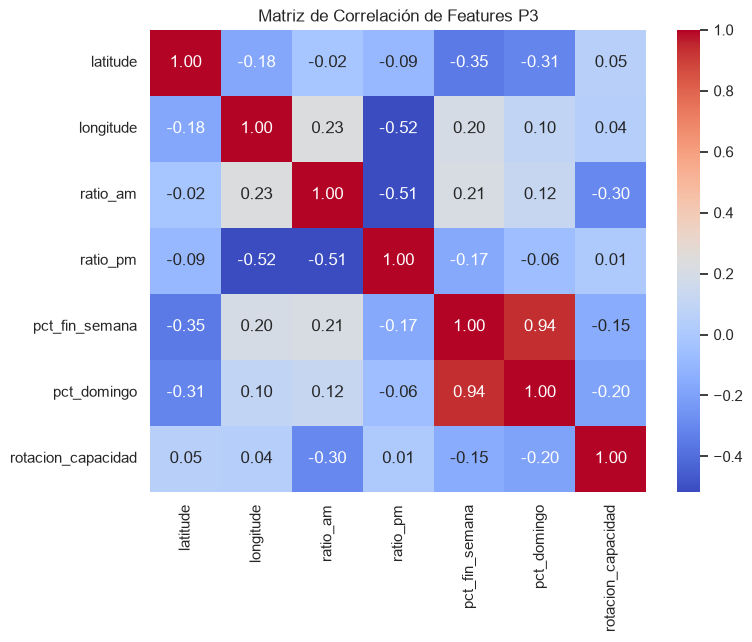

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(station_features.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Matriz de Correlación de Features P3")
plt.show()

## 6. Validación de Consistencia para Modelado
Comprobamos que no existan valores nulos, infinitos ni estaciones desconectadas antes de que `trainp3.py` consuma estos datos para el pipeline de MLflow.

In [9]:
null_counts = station_features.isnull().sum()
inf_counts = np.isinf(station_features).sum()

print("Valores Nulos:")
print(null_counts)
print("\nValores Infinitos:")
print(inf_counts)

assert null_counts.sum() == 0, "Existen valores nulos en la matriz de features."
assert inf_counts.sum() == 0, "Existen valores infinitos en la matriz de features."
print("\nMatriz de características validada con éxito. Lista para entrenamiento en modeling/trainp3.py.")

Valores Nulos:
latitude              0
longitude             0
ratio_am              0
ratio_pm              0
pct_fin_semana        0
pct_domingo           0
rotacion_capacidad    0
dtype: int64

Valores Infinitos:
latitude              0
longitude             0
ratio_am              0
ratio_pm              0
pct_fin_semana        0
pct_domingo           0
rotacion_capacidad    0
dtype: int64

Matriz de características validada con éxito. Lista para entrenamiento en modeling/trainp3.py.
